# Exploratory Data Analysis — Pharmacy Inventory & Medicine Demand Analytics

This notebook covers **descriptive analytics** (what happened) and **diagnostic analytics** (why it happened).
The predictive stage comes later, in `train_model.py`.

Sections:
1. Load the data from the database
2. Clean and validate it
3. Overall sales trend
4. Best-selling medicines
5. Category analysis
6. Weekday patterns
7. Seasonality
8. Features for the model
9. Findings

In [1]:
import os, sys
sys.path.append(os.path.abspath(".."))   # so we can import app.py and models.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from app import app
from models import db

pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
print("Libraries loaded")

Libraries loaded


## 1. Load the data

We read straight from the SQLite database with a SQL join, so medicine name and category come along with every sale.

In [2]:
with app.app_context():
    sales = pd.read_sql("""
        SELECT s.sale_id, s.sale_date, s.quantity, s.selling_price,
               m.medicine_id, m.medicine_code, m.name, m.category
        FROM sales s
        JOIN medicines m ON m.medicine_id = s.medicine_id
    """, db.engine, parse_dates=["sale_date"])

print("Rows:", len(sales))
sales.head()

Rows: 21946


,sale_id,sale_date,quantity,selling_price,medicine_id,medicine_code,name,category
0,1,2024-10-13,5,2.5,1,MED001,Paracetamol 500mg,Analgesic
1,2,2024-10-13,6,2.5,1,MED001,Paracetamol 500mg,Analgesic
2,3,2024-10-13,6,2.5,1,MED001,Paracetamol 500mg,Analgesic
3,4,2024-10-13,4,4.0,2,MED002,Ibuprofen 400mg,Analgesic
4,5,2024-10-13,4,4.0,2,MED002,Ibuprofen 400mg,Analgesic


In [3]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 21946 entries, 0 to 21945
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_id        21946 non-null  int64         
 1   sale_date      21946 non-null  datetime64[us]
 2   quantity       21946 non-null  int64         
 3   selling_price  21946 non-null  float64       
 4   medicine_id    21946 non-null  int64         
 5   medicine_code  21946 non-null  str           
 6   name           21946 non-null  str           
 7   category       21946 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(3), str(3)
memory usage: 1.3 MB


## 2. Clean and validate

Three checks every dataset needs: missing values, duplicates, and impossible values.

In [4]:
print("Missing values per column:")
print(sales.isna().sum())

print("\nDuplicate rows:", sales.duplicated().sum())
print("Negative or zero quantities:", (sales.quantity <= 0).sum())
print("Date range:", sales.sale_date.min().date(), "to", sales.sale_date.max().date())
print("Days covered:", sales.sale_date.nunique())

Missing values per column:
sale_id          0
sale_date        0
quantity         0
selling_price    0
medicine_id      0
medicine_code    0
name             0
category         0
dtype: int64

Duplicate rows: 0
Negative or zero quantities: 0
Date range: 2024-10-13 to 2026-10-13
Days covered: 731


In [5]:
# revenue is quantity x price, added once here and reused throughout
sales["revenue"] = sales.quantity * sales.selling_price

# daily totals: one row per medicine per day. This is what the ML model will use.
daily = (sales.groupby(["sale_date", "medicine_id", "name", "category"], as_index=False)
              .quantity.sum())

print("Daily rows:", len(daily))
print("Days per medicine (should be identical):")
print(daily.groupby("name").size().describe()[["min", "max"]])

Daily rows: 10965
Days per medicine (should be identical):
min    731.0
max    731.0
dtype: float64


## 3. Overall sales trend

Monthly totals show whether the pharmacy is growing and where the busy periods fall.

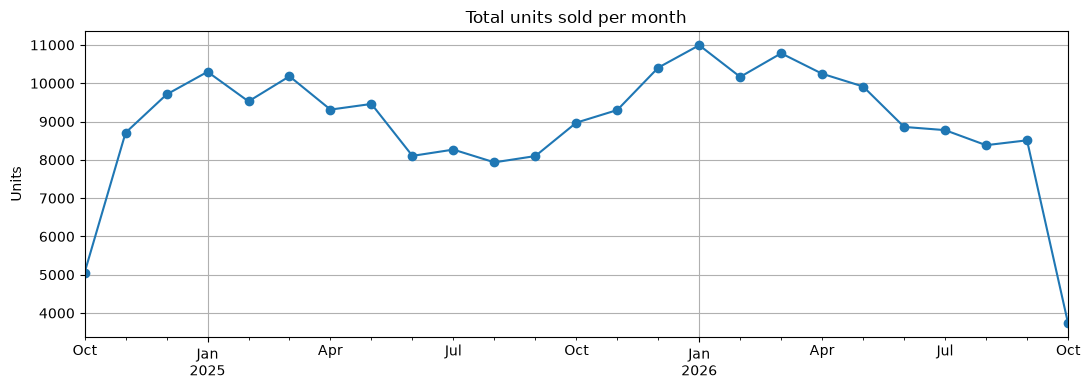

Note: the last month is partial, so it looks lower than it is.


In [6]:
monthly = sales.set_index("sale_date").quantity.resample("ME").sum()

ax = monthly.plot(marker="o")
ax.set_title("Total units sold per month")
ax.set_ylabel("Units")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

print("Note: the last month is partial, so it looks lower than it is.")

## 4. Best-selling medicines

One of the expected outputs of the project.

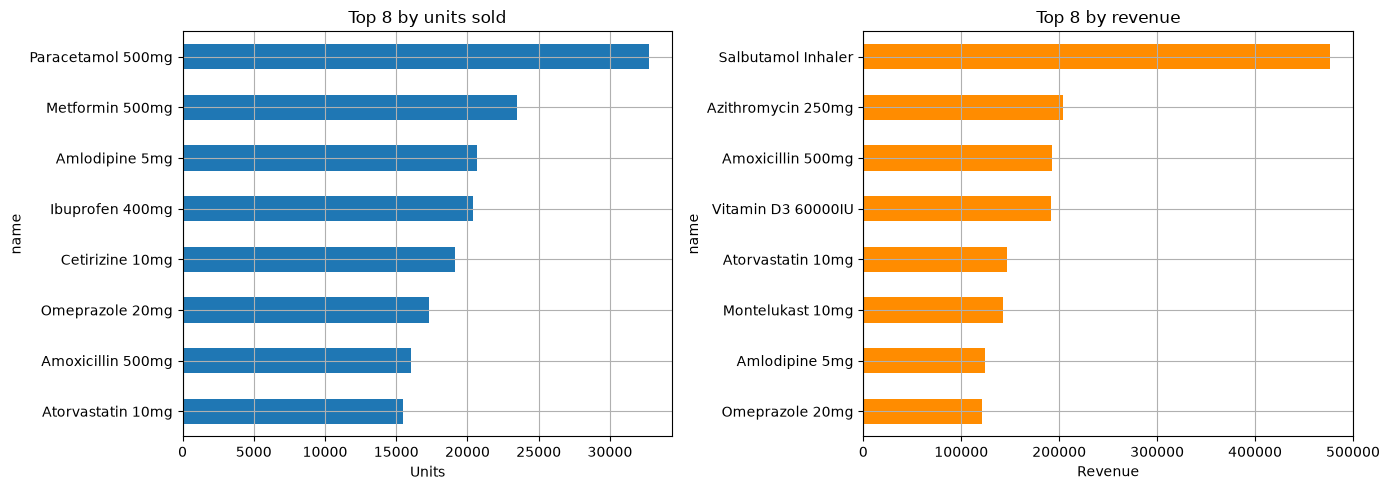

In [7]:
top_qty = sales.groupby("name").quantity.sum().sort_values(ascending=False)
top_rev = sales.groupby("name").revenue.sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_qty.head(8).plot.barh(ax=axes[0]).invert_yaxis()
axes[0].set_title("Top 8 by units sold"); axes[0].set_xlabel("Units")
top_rev.head(8).plot.barh(ax=axes[1], color="darkorange").invert_yaxis()
axes[1].set_title("Top 8 by revenue"); axes[1].set_xlabel("Revenue")
plt.tight_layout(); plt.show()

**Diagnostic point:** the two lists are not the same. Cheap high-volume medicines dominate units sold, while expensive low-volume ones dominate revenue. Stocking decisions driven only by units would under-order the high-value items.

In [8]:
compare = pd.DataFrame({"units": top_qty, "revenue": top_rev})
compare["rank_units"] = compare.units.rank(ascending=False).astype(int)
compare["rank_revenue"] = compare.revenue.rank(ascending=False).astype(int)
compare["rank_gap"] = compare.rank_units - compare.rank_revenue
compare.sort_values("rank_gap").head(5)

,units,revenue,rank_units,rank_revenue,rank_gap
name,,,,,
Paracetamol 500mg,32752,81880.0,1,10,-9
Cetirizine 10mg,19103,61129.6,5,13,-8
Metformin 500mg,23452,105534.0,2,9,-7
Ibuprofen 400mg,20414,81656.0,4,11,-7
Aspirin 75mg,13040,23472.0,9,15,-6


## 5. Category analysis

Another expected output: category-wise sales.

,units,revenue
category,,
Respiratory,12942,619111.0
Antibiotic,23288,395856.0
Cardiovascular,36128,270836.0
Supplement,8695,191290.0
Analgesic,66206,187008.0
Gastrointestinal,23097,184779.0
Antidiabetic,23452,105534.0
Antihistamine,19103,61129.6
Anti-inflammatory,10800,59400.0


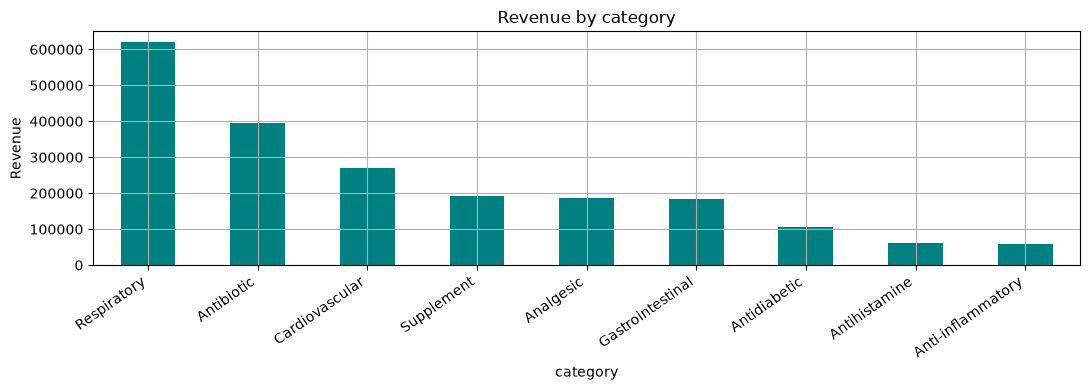

In [9]:
cat = sales.groupby("category").agg(units=("quantity", "sum"),
                                    revenue=("revenue", "sum")).sort_values("revenue",
                                                                            ascending=False)
display(cat)

ax = cat.revenue.plot.bar(color="teal")
ax.set_title("Revenue by category"); ax.set_ylabel("Revenue")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 6. Weekday patterns

This is the first feature we will feed the model.

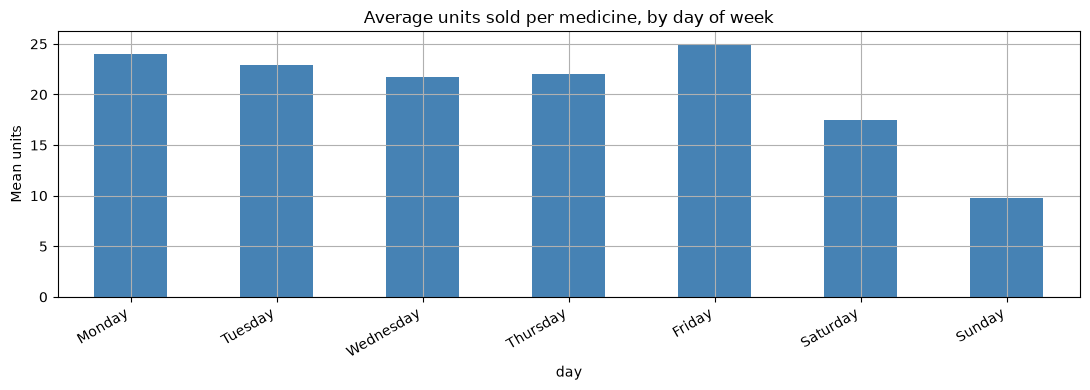

day
Monday       24.0
Tuesday      22.9
Wednesday    21.8
Thursday     22.0
Friday       25.0
Saturday     17.5
Sunday        9.8
Name: quantity, dtype: float64

Sunday is about 59 % below Monday.


In [10]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow = (daily.assign(day=daily.sale_date.dt.day_name())
            .groupby("day").quantity.mean().reindex(order))

ax = dow.plot.bar(color="steelblue")
ax.set_title("Average units sold per medicine, by day of week")
ax.set_ylabel("Mean units")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

print(dow.round(1))
print("\nSunday is about", round(100 * (1 - dow.Sunday / dow.Monday)), "% below Monday.")

## 7. Seasonality

Some medicines peak in winter, others in spring. A model that ignores the month will miss these swings.

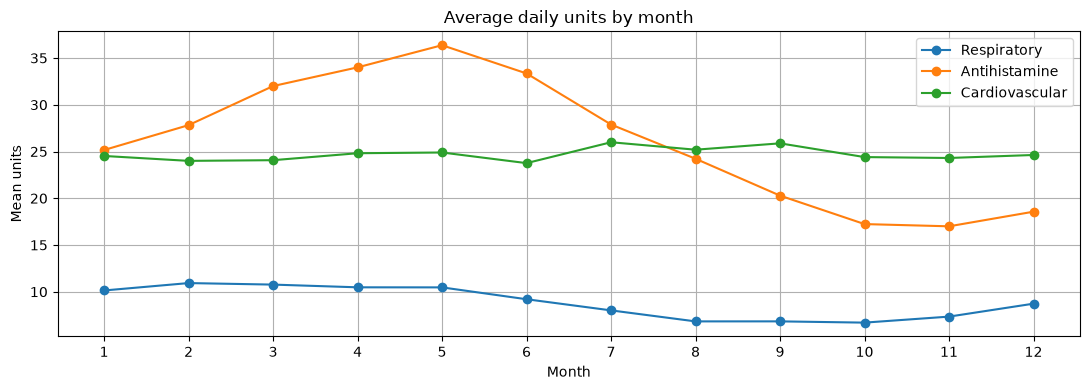

In [11]:
pivot = daily.pivot_table(index=daily.sale_date.dt.month,
                          columns="category", values="quantity", aggfunc="mean")

for col in ["Respiratory", "Antihistamine", "Cardiovascular"]:
    if col in pivot.columns:
        plt.plot(pivot.index, pivot[col], marker="o", label=col)

plt.title("Average daily units by month")
plt.xlabel("Month"); plt.ylabel("Mean units"); plt.legend()
plt.xticks(range(1, 13)); plt.tight_layout(); plt.show()

In [12]:
# how strongly does each medicine swing across the year?
swing = (daily.assign(month=daily.sale_date.dt.month)
              .groupby(["name", "month"]).quantity.mean()
              .groupby("name").agg(["min", "max"]))
swing["swing_pct"] = (100 * (swing["max"] - swing["min"]) / swing["min"]).round(0)
swing.sort_values("swing_pct", ascending=False).head(6)

,min,max,swing_pct
name,,,
Amoxicillin 500mg,12.096774,32.274194,167.0
Paracetamol 500mg,25.354839,65.354839,158.0
Salbutamol Inhaler,3.951613,10.016129,153.0
Azithromycin 250mg,5.822581,14.642857,151.0
Vitamin D3 60000IU,6.870968,16.517857,140.0
Cetirizine 10mg,17.000000,36.370968,114.0


**Diagnostic point:** the medicines with the widest seasonal swing are the ones most at risk of both stockouts and expiry write-offs, because a single fixed reorder level is wrong for them half the year.

## 8. Features for the model

Demand tomorrow depends heavily on demand over the past week. We check that before building the features.

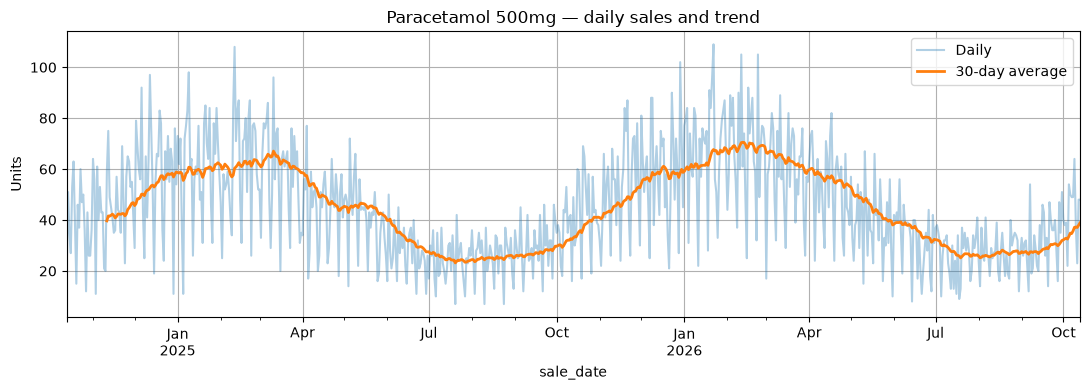

In [13]:
one = daily[daily.name == "Paracetamol 500mg"].set_index("sale_date").quantity

fig, ax = plt.subplots()
one.plot(ax=ax, alpha=0.35, label="Daily")
one.rolling(30).mean().plot(ax=ax, linewidth=2, label="30-day average")
ax.set_title("Paracetamol 500mg — daily sales and trend")
ax.set_ylabel("Units"); ax.legend(); plt.tight_layout(); plt.show()

In [14]:
# autocorrelation: how similar is today to N days ago?
lags = {f"lag_{k}": one.autocorr(lag=k).round(3) for k in [1, 2, 7, 14, 28, 365]}
print("Correlation of sales with earlier days:")
for k, v in lags.items():
    print(f"  {k:8} {v}")

Correlation of sales with earlier days:
  lag_1    0.498
  lag_2    0.379
  lag_7    0.766
  lag_14   0.758
  lag_28   0.713
  lag_365  0.494


The lag-7 correlation is the useful one: the same weekday a week ago is a strong predictor. That is why `lag_7` and `roll_mean_7` become features in the model.

**Planned features:** day of week, month, day of month, week of year, `lag_1`, `lag_7`, `lag_14`, `roll_mean_7`, `roll_mean_28`, plus one-hot encoded medicine.

## 9. Findings

Fill these in with your own numbers after running the notebook.

In [15]:
print("Total units sold      :", f"{sales.quantity.sum():,}")
print("Total revenue         :", f"{sales.revenue.sum():,.0f}")
print("Medicines tracked     :", sales.name.nunique())
print("Categories            :", sales.category.nunique())
print("Days of history       :", sales.sale_date.nunique())
print("Best seller by units  :", top_qty.index[0])
print("Best seller by revenue:", top_rev.index[0])
print("Busiest weekday       :", dow.idxmax())
print("Quietest weekday      :", dow.idxmin())

Total units sold      : 223,711
Total revenue         : 2,074,944
Medicines tracked     : 15
Categories            : 9
Days of history       : 731
Best seller by units  : Paracetamol 500mg
Best seller by revenue: Salbutamol Inhaler
Busiest weekday       : Friday
Quietest weekday      : Sunday


### Summary

1. **Trend** — sales grow slowly across the two years, so the model needs a trend feature.
2. **Weekday effect is strong** — Sunday runs far below weekdays. Day of week must be a feature.
3. **Seasonality is real but uneven** — respiratory and winter medicines swing hardest; flat-selling medicines barely move.
4. **Units and revenue rank differently** — reorder policy should consider both.
5. **Last week predicts this week** — lag and rolling-average features carry most of the signal.

These five points justify every feature used in the prediction step.